# Measurement-based surgery

The whole surgery SED as one cluster state: SED → measurement-based realisation → experiment → circuit. Erasure is on every photon measurement.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from dizx.builders import BUILDERS, surgery_layers
from dizx.circuit_extractor import to_stim
from dizx.dem_view import plot_dem
from dizx.realisation import QECExperiment, RealisedSED
from dizx.schedules import RotatedSurfaceCodeSchedule
from dizx.surgery import two_patch_surgery
from walkthrough import erasure, erasure_sweep, full_and_seam, plot_sweep
from dizx.zx_diagram import SPIDERS

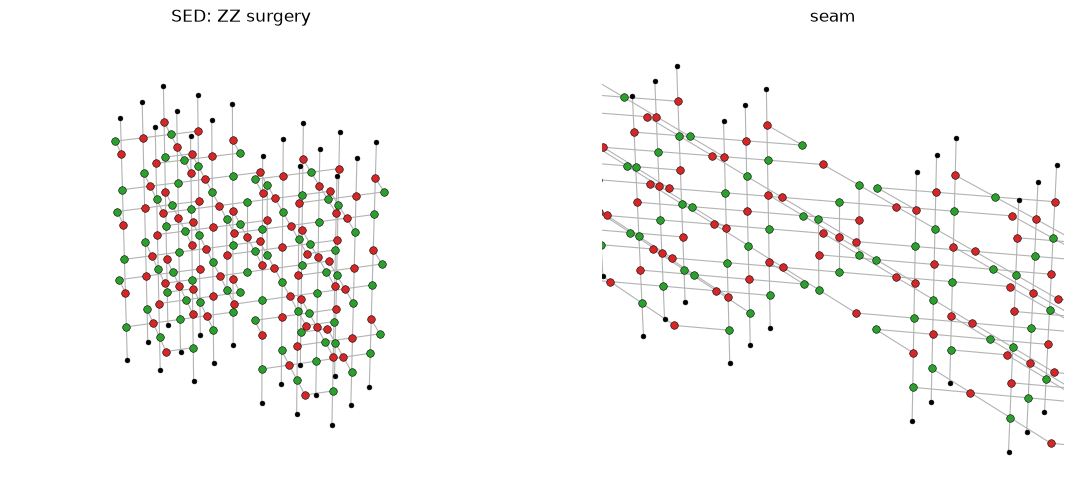

In [2]:
d, n = 3, 1
s = two_patch_surgery(d, "ZZ", layers=surgery_layers(n))
full_and_seam(s.sed, d, "SED: ZZ surgery")

## Realisation: dualise X spiders, every spider a measured qubit

328 cluster qubits


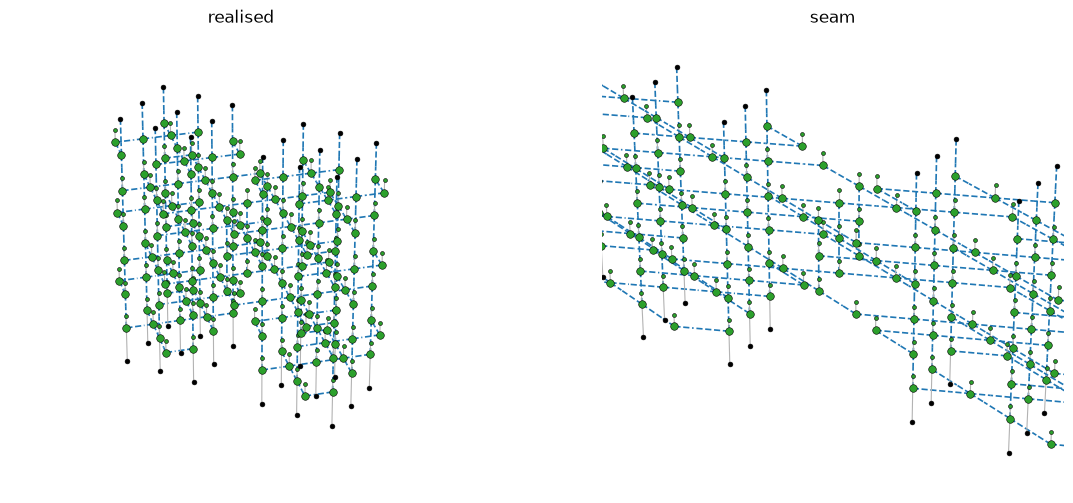

In [3]:
real = RealisedSED.measurement_based(s.sed)
real.graph_region = {v for v, t in real.types.items() if t in SPIDERS}
print(len(real.graph_region), "cluster qubits")
full_and_seam(real, d, "realised")

## Experiment and circuit

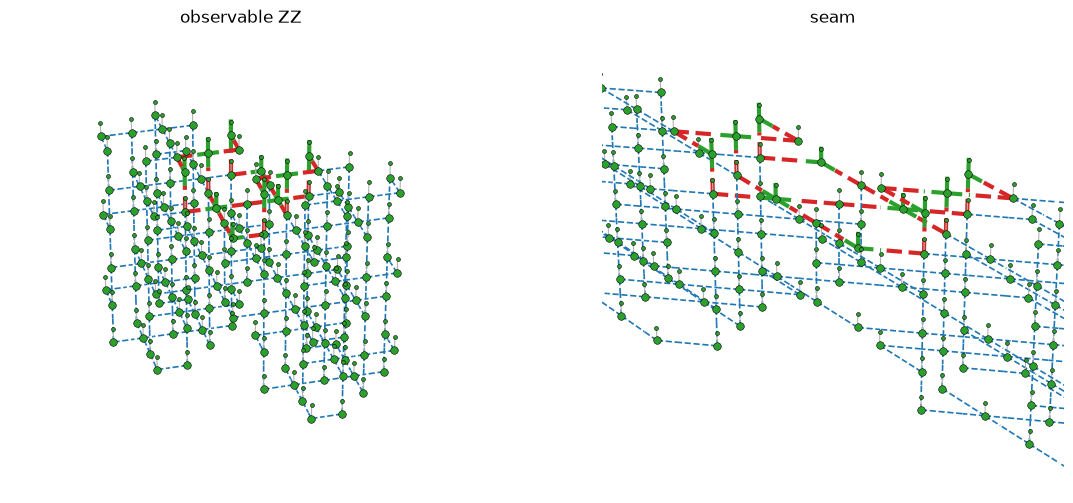

In [4]:
def experiment(real, observable):
    """Patches prepared in X (ZZ merge), measured in the observable's basis."""
    return QECExperiment(real, {p: "X" for p in real.inputs},
                         {p: observable[0] for p in real.outputs})


exp = experiment(real, "ZZ")
full_and_seam(exp, d, "observable ZZ", web=exp.observables[0])

In [5]:
def build(d, n, observable):
    s = two_patch_surgery(d, "ZZ", layers=surgery_layers(n))
    real = RealisedSED.measurement_based(s.sed)
    real.graph_region = {v for v, t in real.types.items() if t in SPIDERS}
    return to_stim(experiment(real, observable), None, fusions="gates")


circuit = build(d, n, "ZZ")
circuit.num_qubits, circuit.num_detectors

(173, 52)

## DEM (measurement erasure)

No interface: every photon can be erased.

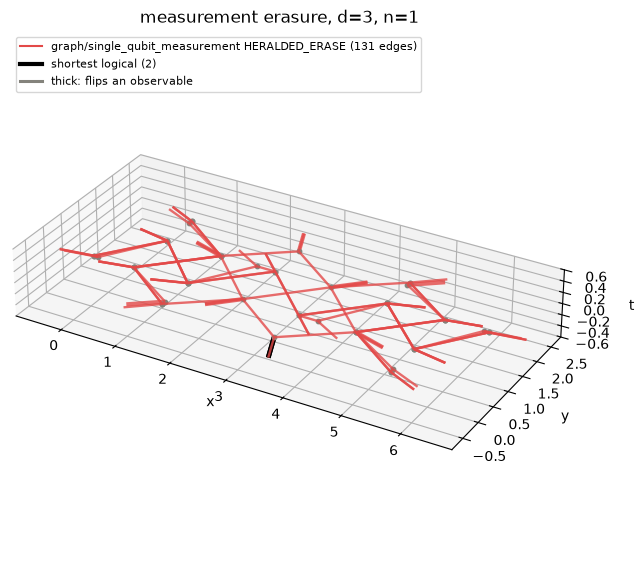

In [6]:
MEAS = ("graph", "single_qubit_measurement")
fig, ax, _ = plot_dem(circuit, erasure(MEAS, 0.1), title="measurement erasure, d=3, n=1")

## Pure erasure sweep

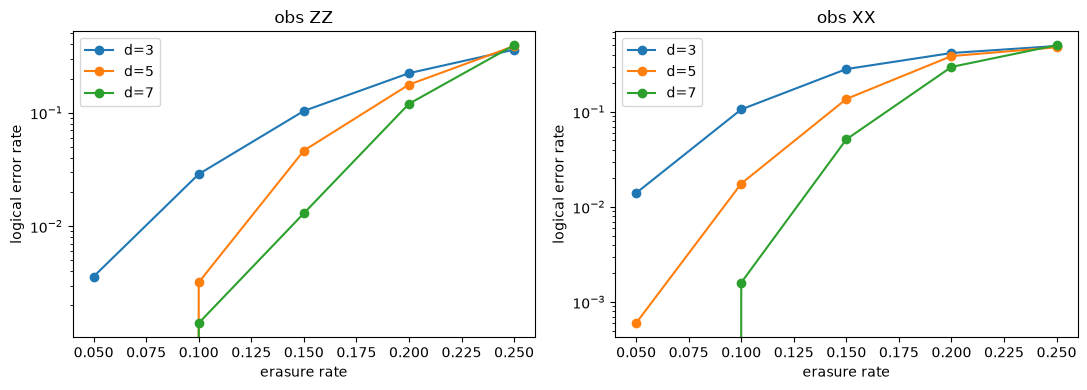

In [7]:
ps = [0.05, 0.1, 0.15, 0.2, 0.25]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, obs in zip(axes, ("ZZ", "XX")):
    rates = erasure_sweep(lambda d: build(d, d, obs), MEAS, [3, 5, 7], ps, shots=5_000)
    plot_sweep(rates, ps, ax=ax, title=f"obs {obs}")
fig.tight_layout()